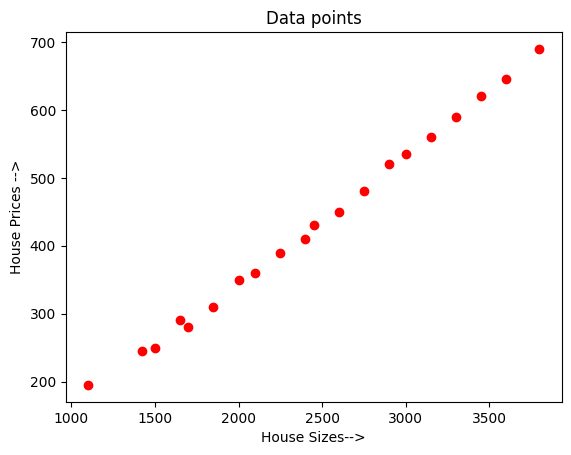

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# House sizes in square feet (will be divided by 1000 in your code -> 1.1 to 3.8)
house_size = [
    1100, 1420, 1500, 1650, 1700, 1850, 2000, 2100, 2250, 2400,
    2450, 2600, 2750, 2900, 3000, 3150, 3300, 3450, 3600, 3800
]

# House prices (in thousands) matching the sizes with a bit of noise
house_price = [
    195, 245, 250, 290, 280, 310, 350, 360, 390, 410,
    430, 450, 480, 520, 535, 560, 590, 620, 645, 690
]

plt.scatter(house_size, house_price, marker='o', color = 'Red')
plt.xlabel('House Sizes-->')
plt.ylabel('House Prices -->')
plt.title('Data points')
plt.show()

In [2]:
x = [i/1000 for i in house_size] #house_size
y = [i/1000 for i in house_price] #house_price

def l(w0,w1,length):

    summation_of_errors = 0

    for i in range(length):
        prediction_ycap_i = (w0+w1*x[i])
        reality_y_i = y[i]
        error = (reality_y_i - prediction_ycap_i)**2

        summation_of_errors = summation_of_errors + error

    return 1/(2*length) * summation_of_errors

def gradients(w0,w1,length):

    summation_of_error_w0=0
    summation_of_error_w1=0
    for i in range(length):
        prediction_ycap_i = (w0 + w1*x[i])
        reality_y_i = y[i]
        error = reality_y_i - prediction_ycap_i

        summation_of_error_w0 = summation_of_error_w0 + error
        summation_of_error_w1 = summation_of_error_w1 + (error * x[i])

    partial_derivative_of_w0 = -1/length* summation_of_error_w0
    partial_derivative_of_w1 = -1/length* summation_of_error_w1
    return np.array([partial_derivative_of_w0, partial_derivative_of_w1])


In [3]:
w = np.array([0,0])
k=0
tol=1e-6
alpha=0.1
max_iter=1000
lengthy = len(x)

#new
beta=0.9
v= 0

In [4]:
history_of_w0 = [w[0]]
history_of_w1 = [w[1]]
history_of_z = [l(w[0], w[1], length=lengthy)]

In [5]:
while np.linalg.norm(gradients(w[0],w[1],length=lengthy))>tol and max_iter>k:

    #gradient:
    grad = gradients(w[0], w[1], length=lengthy)

    #velocity:
    v1 = (beta * v) + (alpha * grad)

    #newpos:
    new_pos = w - v1

    #update:
    w = new_pos

    history_of_w0.append(w[0])
    history_of_w1.append(w[1])
    history_of_z.append(l(w[0],w[1], length=lengthy))

    v = v1

    k +=1

    print(f'[Epoch {k}]: Current Height {l(w[0],w[1],length=lengthy)}, Current Knobs: {w}')

[Epoch 1]: Current Height 0.0067157233505969255, Current Knobs: [0.043    0.116167]
[Epoch 2]: Current Height 0.038720392390905405, Current Knobs: [0.09195651 0.24992141]
[Epoch 3]: Current Height 0.08864435432715811, Current Knobs: [0.10862846 0.29951116]
[Epoch 4]: Current Height 0.027647269423739265, Current Knobs: [0.08243506 0.23664205]
[Epoch 5]: Current Height 0.0062577060126683725, Current Knobs: [0.0356757  0.12033937]
[Epoch 6]: Current Height 0.05678720726155887, Current Knobs: [0.0035596  0.04391913]
[Epoch 7]: Current Height 0.041766483060212425, Current Knobs: [0.00654555 0.0615389 ]
[Epoch 8]: Current Height 0.0006316215689297919, Current Knobs: [0.03651055 0.15147029]
[Epoch 9]: Current Height 0.025805599592429188, Current Knobs: [0.0657405 0.2399731]
[Epoch 10]: Current Height 0.04110317682975954, Current Knobs: [0.06971598 0.26180109]
[Epoch 11]: Current Height 0.00800614096582679, Current Knobs: [0.04522033 0.20828619]
[Epoch 12]: Current Height 0.006574001877605696,

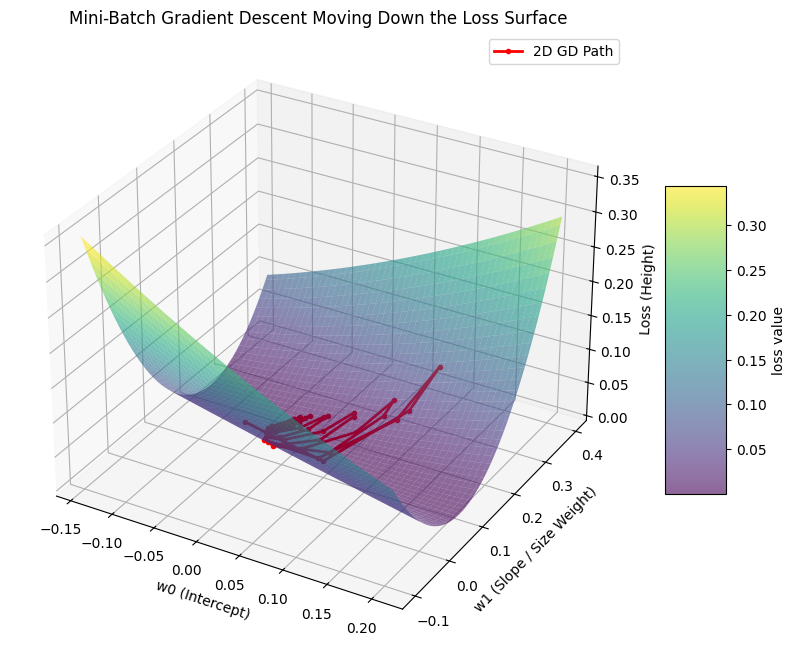

[]

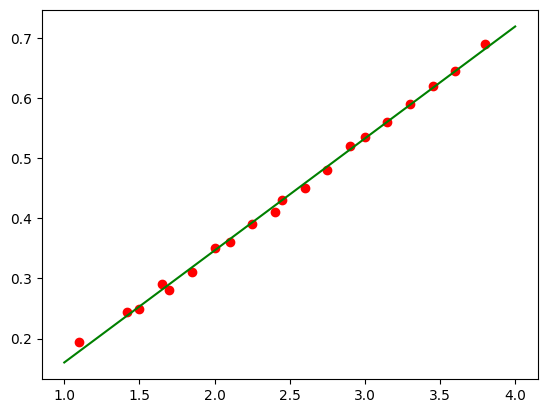

In [7]:
fig = plt.figure( figsize= (10,8))
ax = fig.add_subplot(projection='3d')

X_surf = np.linspace(min(history_of_w0)-0.1, max(history_of_w0)+0.1,100)
Y_surf = np.linspace(min(history_of_w1)-0.1, max(history_of_w1)+0.1,100)
X,Y = np.meshgrid(X_surf,Y_surf)
Z = l(X, Y, length= lengthy)

surf = ax.plot_surface(X,Y,Z, cmap='viridis', alpha=0.6)
fig.colorbar(surf, ax=ax, shrink= 0.5, aspect=5, label='loss value')

ax.plot(history_of_w0, history_of_w1, history_of_z, color = 'Red', marker='.', linewidth = 2,label='2D GD Path')

ax.set_xlabel('w0 (Intercept)')
ax.set_ylabel('w1 (Slope / Size Weight)')
ax.set_zlabel('Loss (Height)')
ax.set_title('Mini-Batch Gradient Descent Moving Down the Loss Surface')
ax.legend()
plt.show()


#plotting the line:
plt.scatter(x,y, color='Red', marker='o')

X = np.linspace(1,4,100)
Y = w[0] + w[1] * X
plt.plot(X,Y, color='Green')
plt.plot()